In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import xarray as xr

from cordex2energy_analysis.analysis import load_warming_level_periods
from cordex2energy_analysis.extreme_value import (
    calculate_climatological_baseline,
    compile_and_compare_periods,
    compute_comprehensive_event_metrics,
    compute_continuous_system_metrics,
    extract_evt_duration_severity_records,
    resolve_gwl_period_definitions,
)
from cordex2energy_analysis.plotting_extremes import resolve_model_periods
from cordex2energy_analysis.extremes_thresholds import compute_active_threshold
from cordex2energy.utils.constants import (
    END_CENTURY_PERIOD,
    MID_CENTURY_PERIOD,
    REFERENCE_PERIOD,
)

sns.set_style("whitegrid", {"grid.color": ".93"})

ERROR 1: PROJ: proj_create_from_database: Open of /home/yhaddad/.conda/envs/c2e-analysis/share/proj failed


In [3]:
paths = json.load(open("../paths.json"))
path_data_processed = Path(paths["path_data_processed"])
path_data_extremes  = path_data_processed / "extremes"
path_residual_load  = path_data_extremes / "residual_load"

# Configuration

In [4]:
climate_scenario = "rcp85"
demand_scenario  = "DE"
demand_year      = 2050
supply_scenario  = "HIGH"
supply_year      = 2040
rolling_window_residual_load = 1
use_reservoir_hydro    = True
use_batteries          = True
use_prosumer_batteries = True

run_tag = f"{demand_scenario}_{demand_year}_{supply_scenario}_{supply_year}"
if rolling_window_residual_load and rolling_window_residual_load > 1:
    run_tag += f"_rlsmooth_{rolling_window_residual_load}"
if use_reservoir_hydro:
    run_tag += "_reservoirdispatch"
if use_batteries:
    run_tag += "_batteries"
    if use_prosumer_batteries:
        run_tag += "_prosumer"

# ── Threshold method ──────────────────────────────────────────────────────────
THRESHOLD_METHOD     = "TAILS"   # "EVT" or "TAILS"
USE_CERRA_THRESHOLDS = True
USE_WARMING_LEVELS   = True
WARMING_LEVELS       = [1.5, 2.0, 3.0]

# ── Detection methods to compare ─────────────────────────────────────────────
METHODS        = ["run_length", "spa"]
METHOD_LABELS  = {"run_length": "Run-length", "spa": "SPA"}
METHOD_COLORS  = {"run_length": "#2166AC",    "spa": "#D6604D"}

# Load data

In [5]:
ds_residual_load_zonal = []
ds_components_zonal    = []

for folder in sorted(path_residual_load.glob("*")):
    if not folder.is_dir() or folder.name == "cerra":
        continue
    run_dir = folder / run_tag
    if not run_dir.exists():
        print(f"  Skipping {folder.name}: no '{run_tag}' subfolder")
        continue
    model_name = "_".join(folder.name.split("_")[:-1])
    ds_residual_load_zonal.append(
        xr.open_dataset(run_dir / "residual_load_zonal.nc").expand_dims(dim={"model": [model_name]})
    )
    ds_components_zonal.append(
        xr.open_dataset(run_dir / "components_zonal.nc").expand_dims(dim={"model": [model_name]})
    )

ds_residual_load_zonal = xr.concat(ds_residual_load_zonal, dim="model", join="outer")
ds_components_zonal    = xr.concat(ds_components_zonal,    dim="model", join="outer")
print(f"Loaded {len(ds_residual_load_zonal.model)} models for run '{run_tag}'")

Loaded 9 models for run 'DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer'


# Setup

In [6]:
season_map = {
    3:"MAM", 4:"MAM",  5:"MAM",
    6:"JJA", 7:"JJA",  8:"JJA",
    9:"SON", 10:"SON", 11:"SON",
    12:"DJF", 1:"DJF",  2:"DJF",
}
season_order = ["DJF", "MAM", "JJA", "SON"]

period_defs = {
    "Reference":   (REFERENCE_PERIOD[0],   REFERENCE_PERIOD[1]),
    "Mid-Century": (MID_CENTURY_PERIOD[0], MID_CENTURY_PERIOD[1]),
    "End-Century": (END_CENTURY_PERIOD[0], END_CENTURY_PERIOD[1]),
}
PERIOD_LABEL = {
    "Reference":   "1_Reference",
    "Mid-Century": "2_Mid-Century",
    "End-Century": "3_End-Century",
}
PERIOD_SHORT = {v: k for k, v in PERIOD_LABEL.items()}
period_colors = {
    "Reference":   "#4A90E2",
    "Mid-Century": "#F5A623",
    "End-Century": "#E24A4A",
}

zones    = ds_residual_load_zonal["zone"].values
models   = ds_residual_load_zonal["model"].values
n_models = len(models)
print(f"Zones  : {zones}")
print(f"Models : {n_models}")

Zones  : ['British_Isles' 'Central_Eastern' 'Central_Western' 'Iberian_Peninsula'
 'Nordic' 'South_East']
Models : 9


In [7]:
if USE_WARMING_LEVELS:
    period_defs, PERIOD_LABEL, period_colors = resolve_gwl_period_definitions(
        warming_levels=WARMING_LEVELS,
        models=models,
        chain_meta_path="../models.json",
        gwl_yaml_path=path_data_processed / "cmip5_warming_levels_all_ens_1861_1900.yml",
        climate_scenario=climate_scenario,
    )
    PERIOD_SHORT = {v: k for k, v in PERIOD_LABEL.items()}
    print(f"GWL periods ({climate_scenario}): {list(period_defs.keys())}")
else:
    print(f"Fixed periods: {list(period_defs.keys())}")

GWL periods (rcp85): ['+1.5°C', '+2.0°C', '+3.0°C']


## Threshold calibration

In [8]:
import time

if USE_CERRA_THRESHOLDS:
    _cerra_run_dir = path_residual_load / "cerra" / run_tag
    print(f"Loading CERRA from: {_cerra_run_dir}")
    _ds_rl_c   = xr.open_dataset(_cerra_run_dir / "residual_load_zonal.nc")
    _ds_comp_c = xr.open_dataset(_cerra_run_dir / "components_zonal.nc")
    _common_c  = np.intersect1d(_ds_rl_c.time.values, _ds_comp_c.time.values)
    _ds_rl_c   = _ds_rl_c.sel(time=_common_c)
    _ds_comp_c = _ds_comp_c.sel(time=_common_c)
    _ds_clim_c = calculate_climatological_baseline(_ds_comp_c)
    _ds_met_c  = compute_continuous_system_metrics(_ds_rl_c, _ds_comp_c, _ds_clim_c)
    _t0 = time.perf_counter()
    da_cerra_threshold = compute_active_threshold(_ds_met_c["residual_load"], THRESHOLD_METHOD)
    print(
        f"CERRA {THRESHOLD_METHOD} thresholds (GWh): "
        + "{" + ", ".join(
            f"{z}: {float(da_cerra_threshold.sel(zone=z)):.1f}"
            for z in da_cerra_threshold.zone.values
        ) + "}"
        + f"  [{time.perf_counter() - _t0:.1f}s]"
    )
else:
    da_cerra_threshold = None
    print("Using per-model thresholds (calibrated in the loop below)")

Loading CERRA from: /net/exo/landclim/yhaddad/clim2energy-ch/extremes/residual_load/cerra/DE_2050_HIGH_2040_reservoirdispatch_batteries_prosumer
CERRA TAILS thresholds (GWh): {British_Isles: 163.3, Central_Eastern: 227.1, Central_Western: 520.5, Iberian_Peninsula: 67.6, Nordic: 0.2, South_East: 172.1}  [23.6s]


## Compute event metrics for both methods

For every model chain and GWL period the comprehensive event metrics are computed twice —
once with each detection algorithm — so downstream comparisons are always paired on identical
climate data and thresholds.

In [9]:
all_results      = {m: [] for m in METHODS}
active_thresholds = {}
_cache_rl        = {}
_cache_comp      = {}

da_zero_thr = xr.DataArray(np.zeros(len(zones)), coords={"zone": zones}, dims=["zone"])
_thr_source = "CERRA" if USE_CERRA_THRESHOLDS else "model-specific"

for model in models:
    print(f"\n── {model}")

    ds_rl_m = (
        ds_residual_load_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    ds_comp_m = (
        ds_components_zonal.sel(model=model)
        .drop_vars("model", errors="ignore")
        .dropna("time", how="all")
    )
    _common_time = np.intersect1d(ds_rl_m.time.values, ds_comp_m.time.values)
    ds_rl_m   = ds_rl_m.sel(time=_common_time)
    ds_comp_m = ds_comp_m.sel(time=_common_time)

    ds_clim = calculate_climatological_baseline(ds_comp_m.sel(time=slice(*REFERENCE_PERIOD)))

    t0_ref, t1_ref = REFERENCE_PERIOD
    ds_rl_ref   = ds_rl_m.sel(time=slice(t0_ref, t1_ref))
    ds_comp_ref = ds_comp_m.sel(time=slice(t0_ref, t1_ref))
    ds_met_ref  = compute_continuous_system_metrics(ds_rl_ref, ds_comp_ref, ds_clim)

    da_active = (
        da_cerra_threshold if USE_CERRA_THRESHOLDS
        else compute_active_threshold(ds_met_ref["residual_load"], THRESHOLD_METHOD)
    )
    active_thresholds[model] = da_active

    resolved_periods = {
        k: v for k, v in resolve_model_periods(period_defs, model).items()
        if v is not None
    }

    period_res = {m: {} for m in METHODS}
    for period_name, (t0, t1) in resolved_periods.items():
        ds_rl_p   = ds_rl_m.sel(time=slice(t0, t1))
        ds_comp_p = ds_comp_m.sel(time=slice(t0, t1))
        ds_met_p  = compute_continuous_system_metrics(ds_rl_p, ds_comp_p, ds_clim)
        print(f"  {period_name} ...", end=" ", flush=True)
        for method in METHODS:
            period_res[method][period_name] = compute_comprehensive_event_metrics(
                ds_met_p, da_active, method=method
            )
        print("done")

    _period_names = [PERIOD_LABEL[k] for k in resolved_periods]
    for method in METHODS:
        df_e, _ = compile_and_compare_periods(
            *[period_res[method][k] for k in resolved_periods],
            period_names=_period_names,
        )
        df_e = df_e.reset_index()
        df_e["model"]  = model
        df_e["method"] = method
        all_results[method].append(df_e)

    _cache_rl[model]   = ds_rl_m
    _cache_comp[model] = ds_comp_m

df_ens = {}
for method in METHODS:
    df        = pd.concat(all_results[method], ignore_index=True)
    df["Period"] = df["Period"].map(PERIOD_SHORT)
    df_ens[method] = df

n_rows = df_ens[METHODS[0]].shape[0]
print(f"\n✓ {n_rows} rows per method  [{THRESHOLD_METHOD} · {_thr_source}]")


── CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1
  +1.5°C ... done
  +2.0°C ... done
  +3.0°C ... done

── CNRM-ALADIN63_MOHC-HadGEM2-ES_r1i1p1
  +1.5°C ... done
  +2.0°C ... done
  +3.0°C ... done

── CNRM-ALADIN63_MPI-M-MPI-ESM-LR_r1i1p1
  +1.5°C ... done
  +2.0°C ... done
  +3.0°C ... done

── CNRM-ALADIN63_NCC-NorESM1-M_r1i1p1
  +1.5°C ... done
  +2.0°C ... done
  +3.0°C ... done

── MOHC-HadREM3-GA7-05_CNRM-CERFACS-CNRM-CM5_r1i1p1
  +1.5°C ... done
  +2.0°C ... done
  +3.0°C ... done

── MOHC-HadREM3-GA7-05_ICHEC-EC-EARTH_r12i1p1
  +1.5°C ... done
  +2.0°C ... done
  +3.0°C ... done

── MOHC-HadREM3-GA7-05_MOHC-HadGEM2-ES_r1i1p1
  +1.5°C ... done
  +2.0°C ... done
  +3.0°C ... done

── MOHC-HadREM3-GA7-05_MPI-M-MPI-ESM-LR_r1i1p1
  +1.5°C ... done
  +2.0°C ... done
  +3.0°C ... done

── MOHC-HadREM3-GA7-05_NCC-NorESM1-M_r1i1p1
  +1.5°C ... done
  +2.0°C ... done
  +3.0°C ... done

✓ 162 rows per method  [TAILS · CERRA]


## Comparison DataFrame

In [10]:
KEY_METRICS = [
    "Frequency",
    "Avg_Duration_Hours",
    "Max_Duration_Hours",
    "Avg_Energy_Severity_GWh",
    "Total_Annual_Energy_Severity_GWh",
    "Max_Single_Event_Severity_GWh",
]

df_compare = df_ens["run_length"].merge(
    df_ens["spa"],
    on=["Zone", "Period", "model"],
    suffixes=("_rl", "_spa"),
)

for col in KEY_METRICS:
    df_compare[f"{col}_ratio"] = (
        df_compare[f"{col}_spa"] / df_compare[f"{col}_rl"].replace(0, np.nan)
    )

print(f"df_compare: {df_compare.shape[0]} rows × {df_compare.shape[1]} cols")
df_compare[
    ["Zone", "Period", "model"]
    + [f"{c}_rl" for c in KEY_METRICS[:3]]
    + [f"{c}_spa" for c in KEY_METRICS[:3]]
].head()

df_compare: 162 rows × 69 cols


,Zone,Period,model,Frequency_rl,Avg_Duration_Hours_rl,Max_Duration_Hours_rl,Frequency_spa,Avg_Duration_Hours_spa,Max_Duration_Hours_spa
0,British_Isles,+1.5°C,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,748,5.294118,18.0,679,8.209131,105.0
1,British_Isles,+2.0°C,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,771,5.245136,21.0,702,8.358974,111.0
2,British_Isles,+3.0°C,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,711,4.864979,18.0,668,7.217066,66.0
3,Central_Eastern,+1.5°C,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,71,6.338028,15.0,61,10.868852,45.0
4,Central_Eastern,+2.0°C,CNRM-ALADIN63_CNRM-CERFACS-CNRM-CM5_r1i1p1,49,6.061224,15.0,46,9.260870,42.0


# Comparison analysis

## Summary statistics

Ensemble median for each metric, zone, and detection method — pooled across all GWL periods.

In [11]:
summary_rows = []
for zone in zones:
    for method in METHODS:
        df_z = df_ens[method][df_ens[method]["Zone"] == zone]
        row  = {"Zone": str(zone), "Method": METHOD_LABELS[method]}
        for col in KEY_METRICS:
            row[col] = df_z[col].median()
        summary_rows.append(row)

df_summary = pd.DataFrame(summary_rows).set_index(["Zone", "Method"])
df_summary[KEY_METRICS].round(1)

Frequency  Avg_Duration_Hours  \
Zone              Method                                      
British_Isles     Run-length      905.0                 5.3   
                  SPA             806.0                 8.7   
Central_Eastern   Run-length       55.0                 7.3   
                  SPA              52.0                11.5   
Central_Western   Run-length      801.0                 6.0   
                  SPA             579.0                12.1   
Iberian_Peninsula Run-length     1059.0                 7.1   
                  SPA             963.0                 8.9   
Nordic            Run-length      645.0                 7.4   
                  SPA             591.0                11.4   
South_East        Run-length      433.0                 4.1   
                  SPA             420.0                 5.2   

                              Max_Duration_Hours  Avg_Energy_Severity_GWh  \
Zone              Method                                                    
British_Isles     Run-length                33.0                    181.3   
                  SPA                      156.0                    202.5   
Central_Eastern   Run-length                18.0                     69.1   
                  SPA                       54.0                     76.6   
Central_Western   Run-length                36.0                    509.3   
                  SPA                      177.0                    704.8   
Iberian_Peninsula Run-length                18.0                     45.0   
                  SPA                       42.0                     49.8   
Nordic            Run-length                51.0                    168.7   
                  SPA                      108.0                    186.0   
South_East        Run-length                 9.0                     44.1   
                  SPA                       18.0                     45.3   

                              Total_Annual_Energy_Severity_GWh  \
Zone              Method                                         
British_Isles     Run-length                            8271.5   
                  SPA                                   8271.5   
Central_Eastern   Run-length                             207.3   
                  SPA                                    207.3   
Central_Western   Run-length                           19301.3   
                  SPA                                  19301.3   
Iberian_Peninsula Run-length                            2623.2   
                  SPA                                   2623.2   
Nordic            Run-length                            5657.2   
                  SPA                                   5657.2   
South_East        Run-length                             969.5   
                  SPA                                    969.5   

                              Max_Single_Event_Severity_GWh  
Zone              Method                                     
British_Isles     Run-length                         2472.2  
                  SPA                                5099.6  
Central_Eastern   Run-length                          383.4  
                  SPA                                 563.6  
Central_Western   Run-length                         6004.7  
                  SPA                               16774.8  
Iberian_Peninsula Run-length                          364.8  
                  SPA                                 451.7  
Nordic            Run-length                         2439.6  
                  SPA                                3132.1  
South_East        Run-length                          276.9  
                  SPA                                 296.5

In [12]:
ratio_cols = [f"{c}_ratio" for c in KEY_METRICS]
df_ratio_tbl = (
    df_compare.groupby("Zone")[ratio_cols]
    .median()
    .rename(columns={f"{c}_ratio": c for c in KEY_METRICS})
    .round(2)
)
print("SPA / run-length ratio — ensemble median (pooled across all periods and models):")
df_ratio_tbl

SPA / run-length ratio — ensemble median (pooled across all periods and models):


,Frequency,Avg_Duration_Hours,Max_Duration_Hours,Avg_Energy_Severity_GWh,Total_Annual_Energy_Severity_GWh,Max_Single_Event_Severity_GWh
Zone,,,,,,
British_Isles,0.90,1.61,5.00,1.11,1.0,1.92
Central_Eastern,0.93,1.53,2.80,1.07,1.0,1.47
Central_Western,0.73,2.00,5.00,1.37,1.0,2.63
Iberian_Peninsula,0.93,1.25,1.89,1.08,1.0,1.00
Nordic,0.91,1.53,2.12,1.10,1.0,1.14
South_East,0.97,1.28,2.00,1.03,1.0,1.00


## Metric distributions by method

Violins show the distribution across all models × GWL periods for each zone.
The inner box marks the IQR; the white dot is the median.

/tmp/ipykernel_589324/3337261140.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_589324/3337261140.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_589324/3337261140.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_589324/3337261140.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_589324/3337261140.py:30: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_589324/3337261140.py:30: UserWarnin

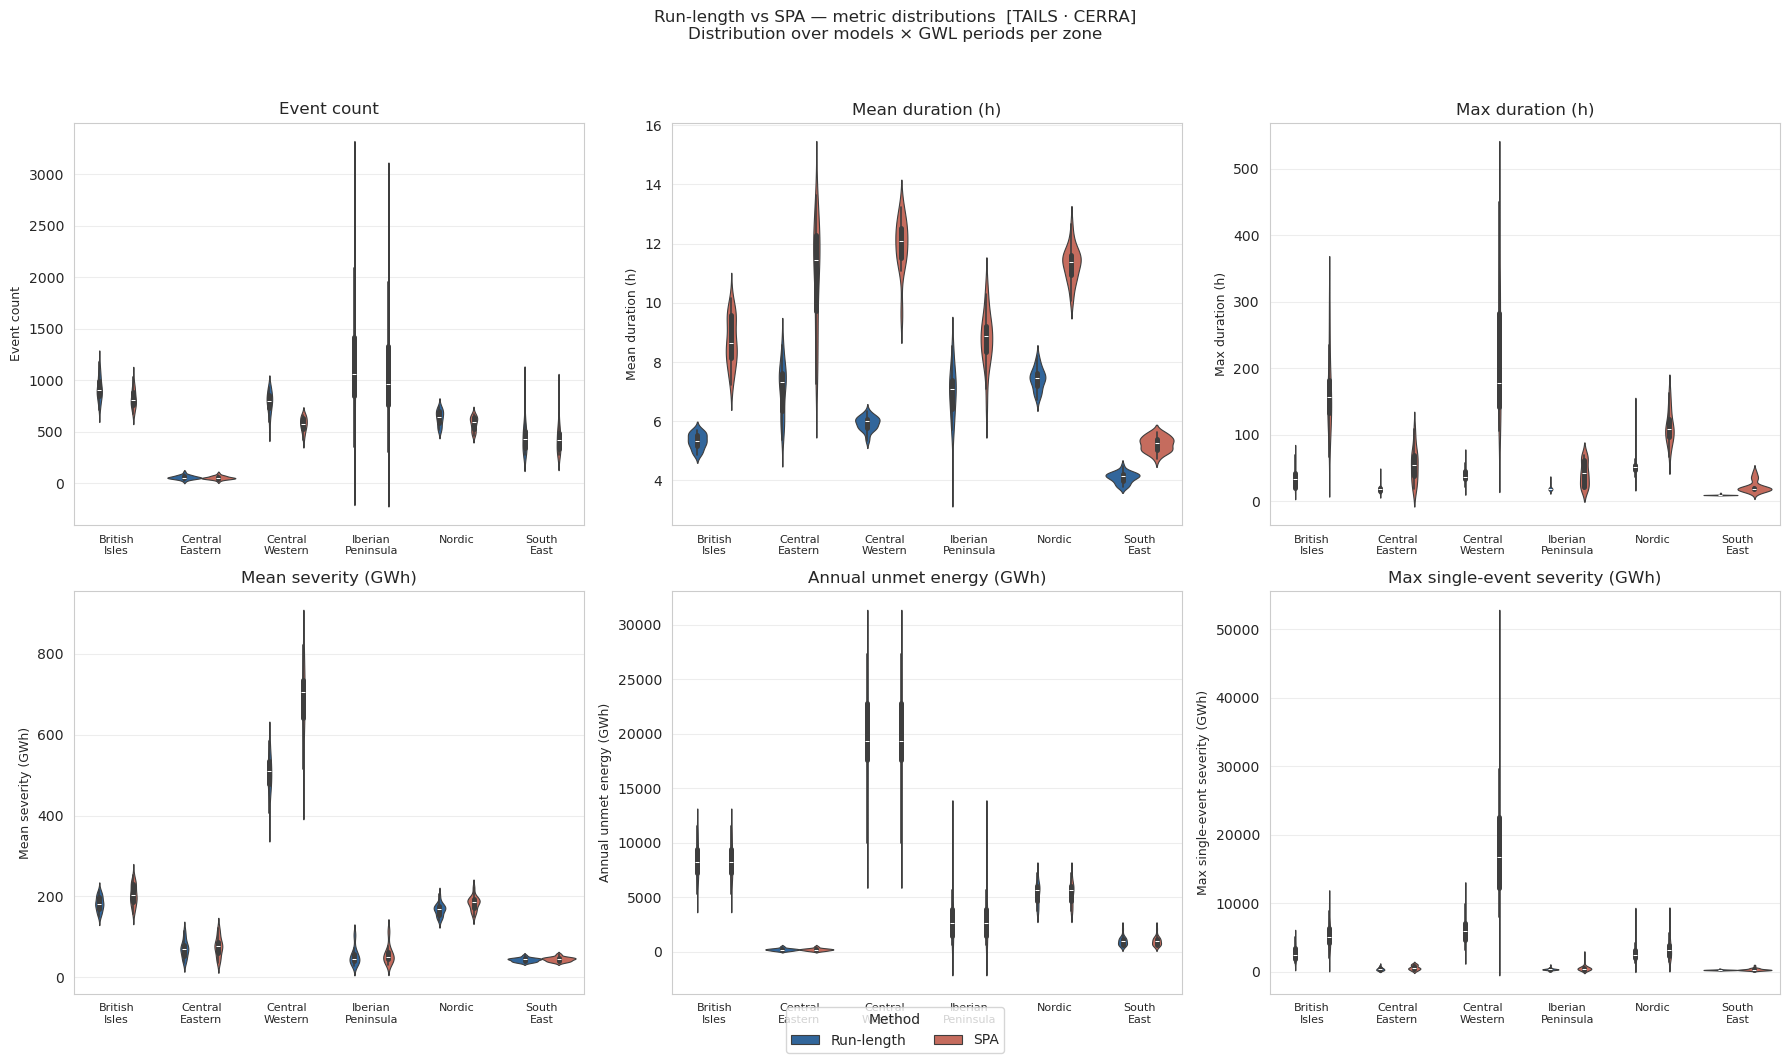

In [13]:
df_long = pd.concat([
    df_ens["run_length"].assign(Method="Run-length"),
    df_ens["spa"].assign(Method="SPA"),
])

METRIC_LABELS = {
    "Frequency":                        "Event count",
    "Avg_Duration_Hours":               "Mean duration (h)",
    "Max_Duration_Hours":               "Max duration (h)",
    "Avg_Energy_Severity_GWh":          "Mean severity (GWh)",
    "Total_Annual_Energy_Severity_GWh": "Annual unmet energy (GWh)",
    "Max_Single_Event_Severity_GWh":    "Max single-event severity (GWh)",
}

# Palette keyed by display labels (matches the Method column)
label_colors = {METHOD_LABELS[m]: METHOD_COLORS[m] for m in METHODS}

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for ax, col in zip(axes, KEY_METRICS):
    sns.violinplot(
        data=df_long,
        x="Zone", y=col, hue="Method",
        palette=label_colors,
        split=False, inner="box",
        linewidth=0.8, ax=ax,
    )
    ax.set_xlabel("")
    ax.set_xticklabels(
        [str(z).replace("_", "\n") for z in zones], fontsize=8
    )
    ax.set_ylabel(METRIC_LABELS[col], fontsize=9)
    ax.set_title(METRIC_LABELS[col])
    ax.get_legend().remove()

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, title="Method", loc="lower center",
           ncol=2, bbox_to_anchor=(0.5, -0.02), fontsize=10)

fig.suptitle(
    f"Run-length vs SPA — metric distributions  [{THRESHOLD_METHOD} · {_thr_source}]\n"
    "Distribution over models × GWL periods per zone",
    fontsize=12, y=1.03,
)
plt.tight_layout()
plt.show()

## Method agreement — scatter plots

Each point is one *(model, zone, GWL period)* tuple.
Points on the dashed diagonal indicate perfect agreement.
Points **above** → SPA yields larger values; **below** → SPA yields smaller values.

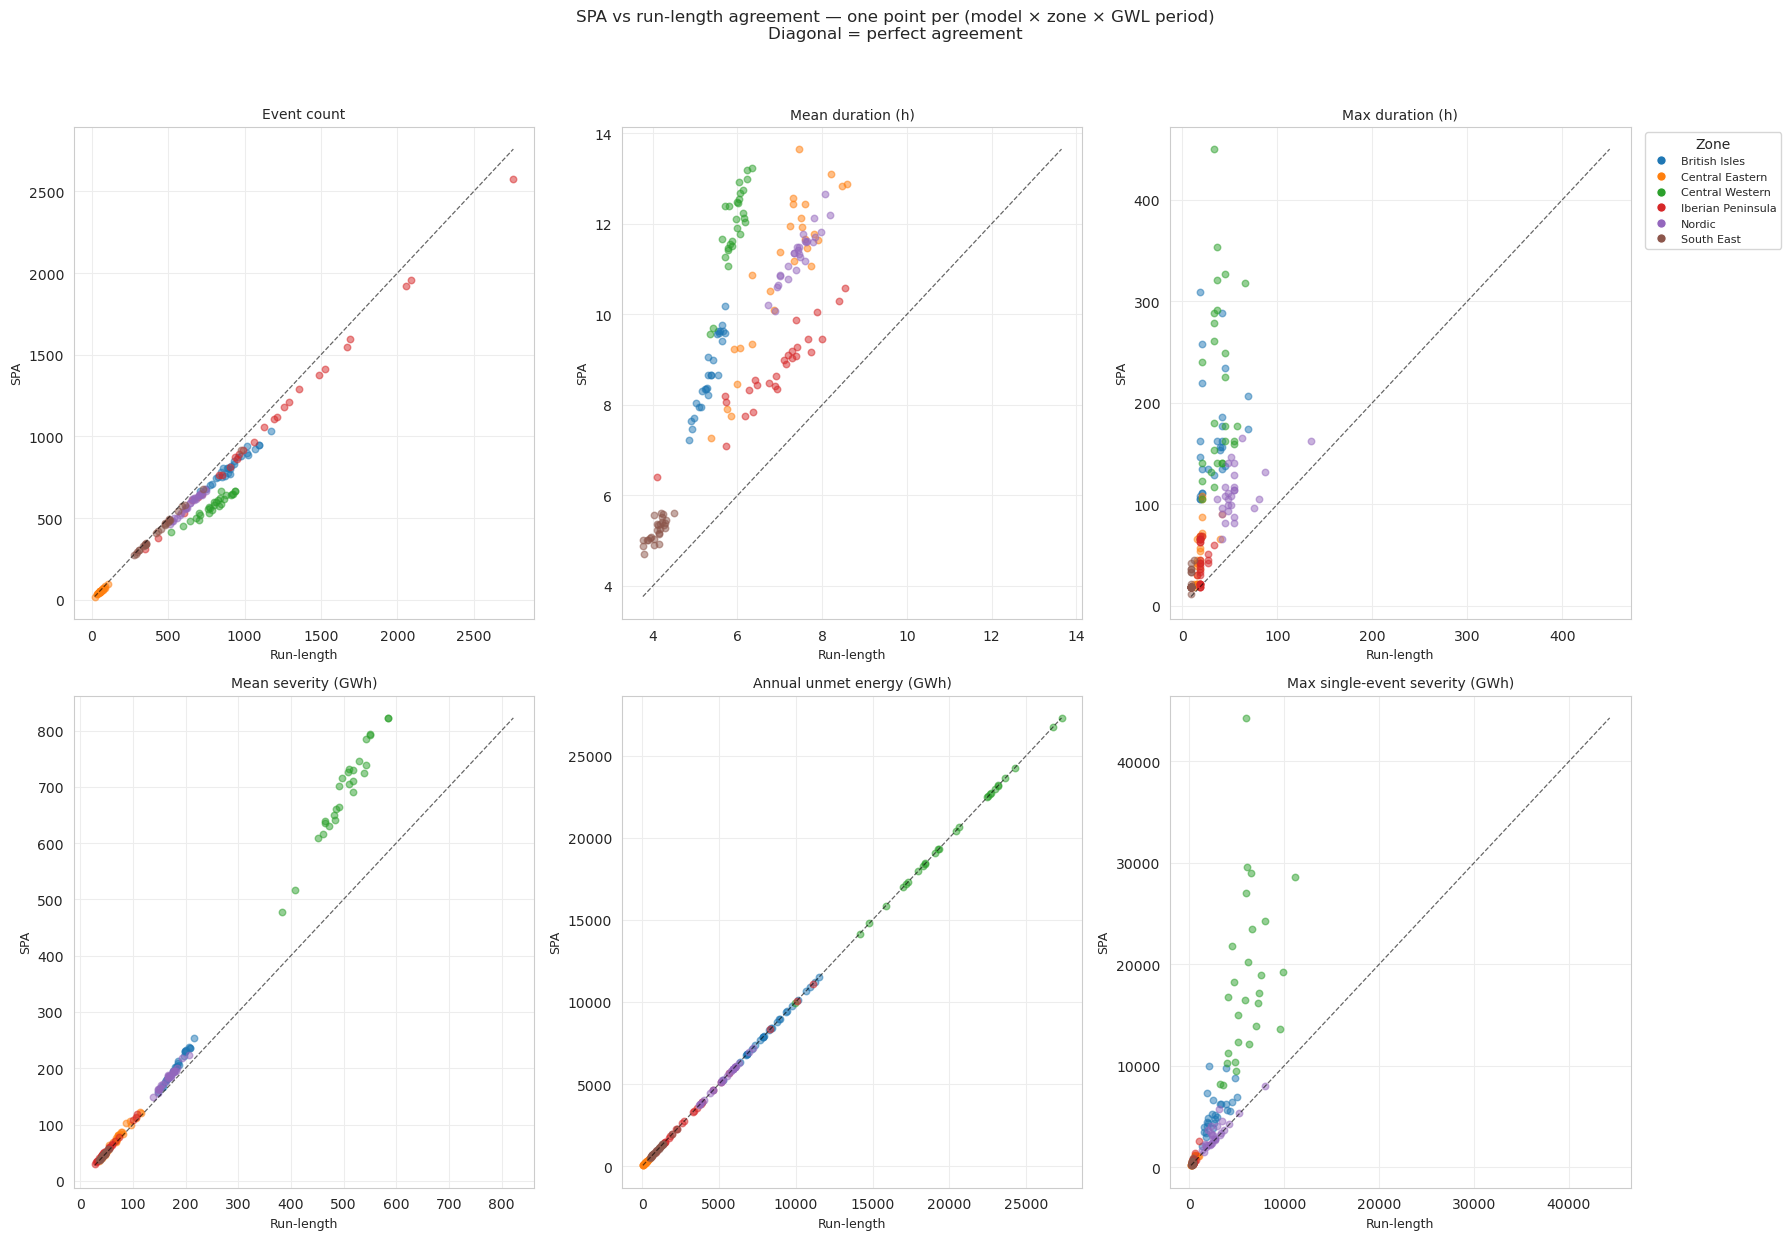

In [14]:
zone_palette = dict(zip(zones, sns.color_palette("tab10", n_colors=len(zones))))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for ax, col in zip(axes, KEY_METRICS):
    for zone, color in zone_palette.items():
        df_z = df_compare[df_compare["Zone"] == zone]
        ax.scatter(
            df_z[f"{col}_rl"], df_z[f"{col}_spa"],
            c=[color], alpha=0.5, s=22, label=str(zone).replace("_", " "),
        )
    # y = x reference line
    combined = pd.concat([df_compare[f"{col}_rl"], df_compare[f"{col}_spa"]]).dropna()
    lo, hi = combined.min(), combined.max()
    ax.plot([lo, hi], [lo, hi], "k--", lw=0.9, alpha=0.6)
    ax.set_xlabel("Run-length", fontsize=9)
    ax.set_ylabel("SPA", fontsize=9)
    ax.set_title(METRIC_LABELS[col], fontsize=10)

handles = [
    plt.Line2D([0], [0], marker="o", color="w",
               markerfacecolor=zone_palette[z], markersize=7,
               label=str(z).replace("_", " "))
    for z in zones
]
axes[2].legend(handles=handles, title="Zone", fontsize=8,
               loc="upper left", bbox_to_anchor=(1.02, 1))

fig.suptitle(
    "SPA vs run-length agreement — one point per (model × zone × GWL period)\n"
    "Diagonal = perfect agreement",
    fontsize=12, y=1.03,
)
plt.tight_layout()
plt.show()

## SPA / run-length ratios by zone and GWL period

Ensemble-median ratio for each (zone, period) cell.
Values < 1 mean SPA yields fewer / shorter / less severe events than run-length;
values > 1 mean the opposite.

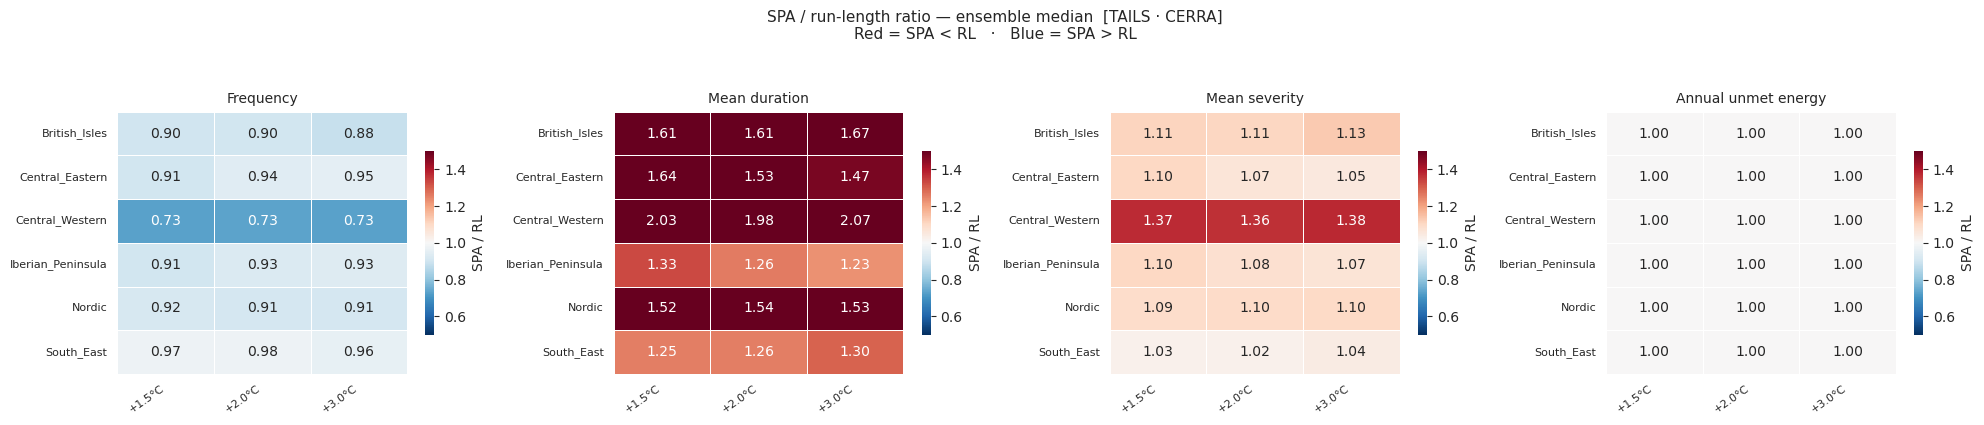

In [15]:
RATIO_METRICS = {
    "Frequency":                        "Frequency",
    "Avg_Duration_Hours":               "Mean duration",
    "Avg_Energy_Severity_GWh":          "Mean severity",
    "Total_Annual_Energy_Severity_GWh": "Annual unmet energy",
}
periods_ordered = list(PERIOD_SHORT.values())

fig, axes = plt.subplots(1, len(RATIO_METRICS), figsize=(5 * len(RATIO_METRICS), 4))

for ax, (col, label) in zip(axes, RATIO_METRICS.items()):
    pivot = (
        df_compare.groupby(["Zone", "Period"])[f"{col}_ratio"]
        .median()
        .unstack("Period")
        .reindex(columns=periods_ordered)
    )
    sns.heatmap(
        pivot, ax=ax,
        cmap="RdBu_r", center=1.0, vmin=0.5, vmax=1.5,
        annot=True, fmt=".2f",
        linewidths=0.5, linecolor="white",
        cbar_kws={"shrink": 0.7, "label": "SPA / RL"},
    )
    ax.set_title(label, fontsize=10)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_xticklabels(ax.get_xticklabels(), rotation=35, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)

fig.suptitle(
    f"SPA / run-length ratio — ensemble median  [{THRESHOLD_METHOD} · {_thr_source}]\n"
    "Red = SPA < RL   ·   Blue = SPA > RL",
    fontsize=11, y=1.05,
)
plt.tight_layout()
plt.show()

## Duration and severity distributions of individual events

Individual event records are extracted for each method using
`extract_evt_duration_severity_records`.  Each panel shows one zone;
dashed vertical lines mark the ensemble median for each method.

In [16]:
dur_records = {}
for method in METHODS:
    dur_records[method] = extract_evt_duration_severity_records(
        _cache_rl, active_thresholds, period_defs, models, zones, method=method
    )
    print(f"  {METHOD_LABELS[method]:>12}: {len(dur_records[method]):,} events")

    Run-length: 108,699 events
           SPA: 95,784 events


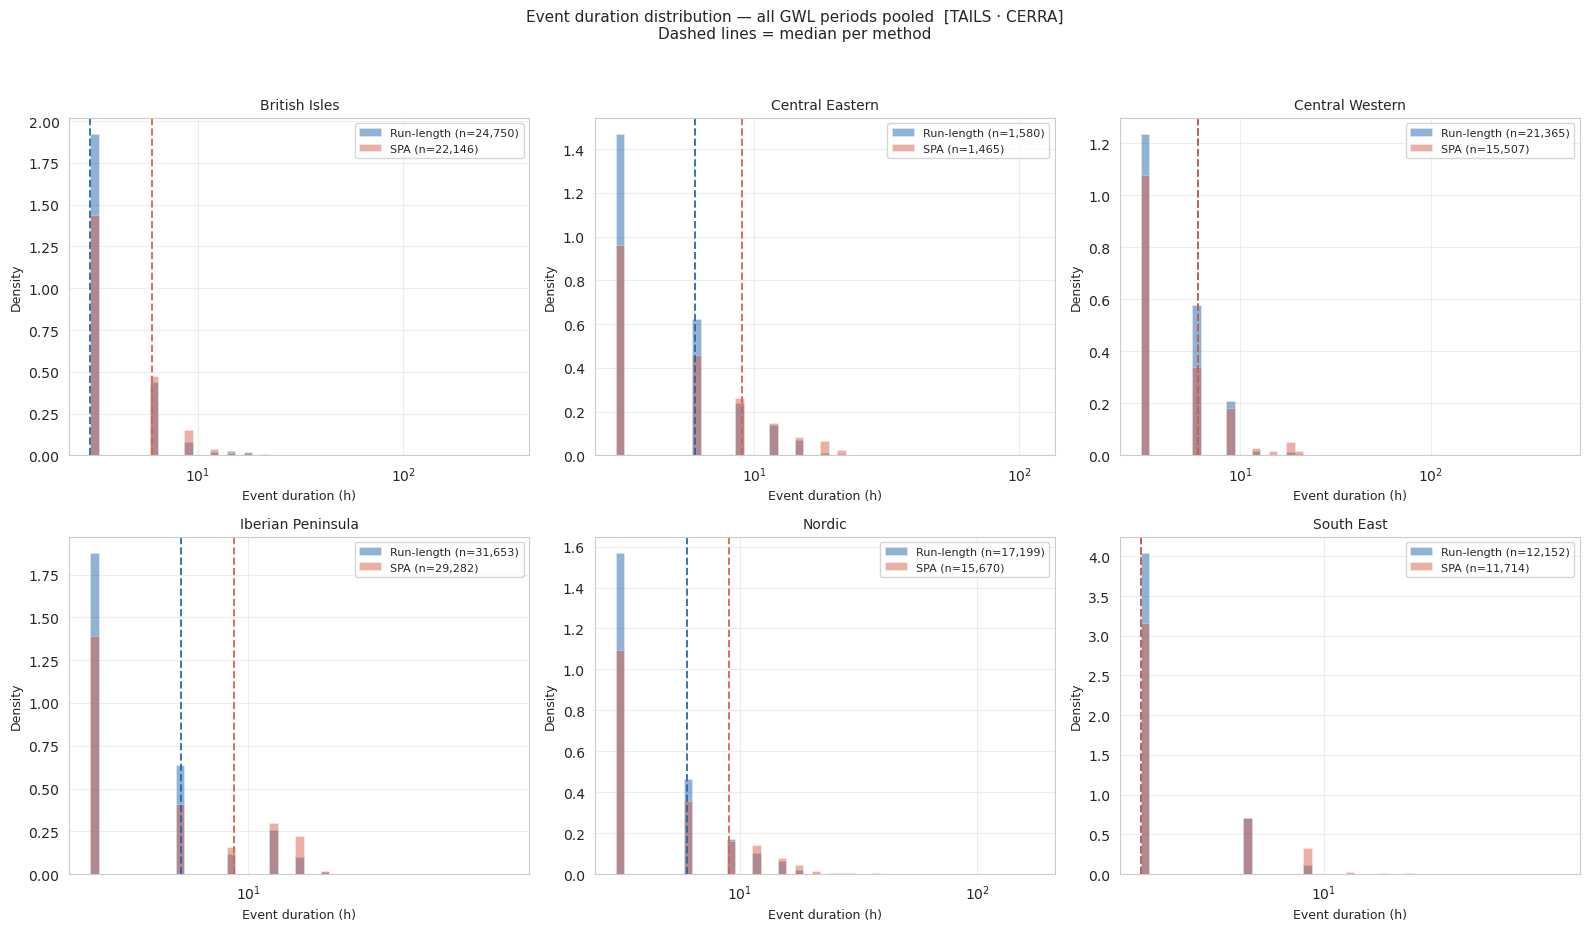

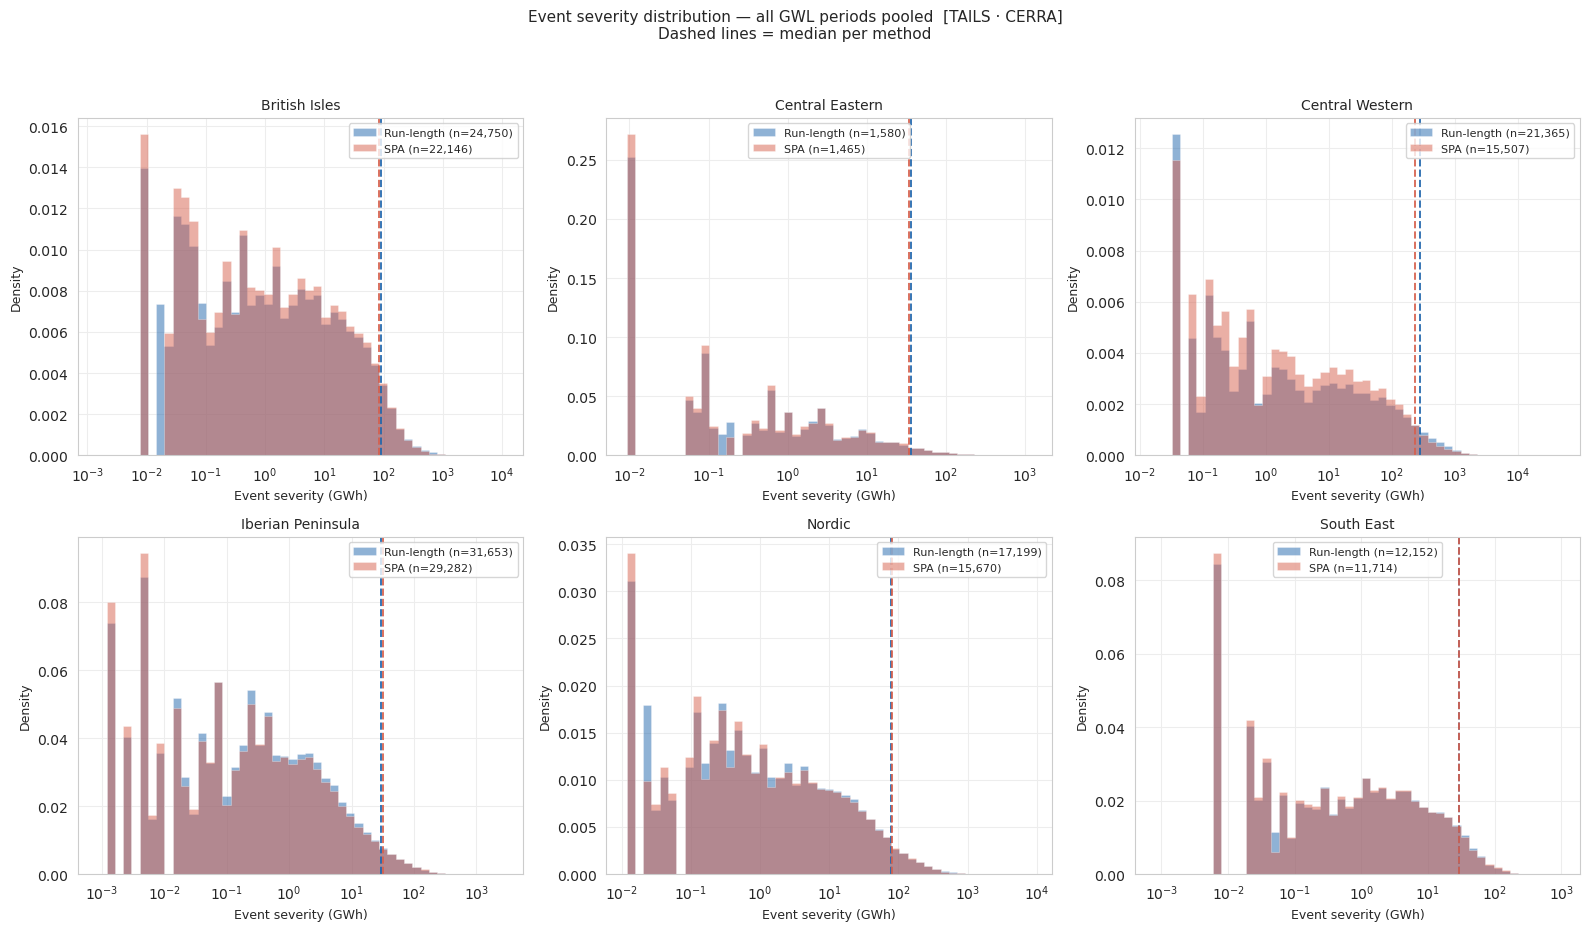

In [17]:
def _plot_event_distributions(metric, xlabel, log_x=True):
    n_cols = 3
    n_rows = int(np.ceil(len(zones) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 4.5 * n_rows))
    axes = axes.flatten()

    for ax, zone in zip(axes, zones):
        zone_str = str(zone)
        all_vals = pd.concat([
            dur_records[m][dur_records[m]["zone"] == zone_str][metric]
            for m in METHODS
        ]).dropna()
        if all_vals.empty:
            continue

        lo = max(all_vals.min(), 1e-9)
        hi = all_vals.max() * 1.05
        bins = (np.logspace(np.log10(lo), np.log10(hi), 50)
                if log_x else np.linspace(lo, hi, 50))

        for method in METHODS:
            vals = dur_records[method][
                dur_records[method]["zone"] == zone_str
            ][metric].dropna().values
            if len(vals) == 0:
                continue
            ax.hist(
                vals, bins=bins, density=True,
                alpha=0.50, color=METHOD_COLORS[method],
                label=f"{METHOD_LABELS[method]} (n={len(vals):,})",
                histtype="stepfilled", edgecolor="white", linewidth=0.4,
            )
            ax.axvline(
                np.median(vals), color=METHOD_COLORS[method],
                ls="--", lw=1.4, alpha=0.9,
            )

        if log_x:
            ax.set_xscale("log")
        ax.set_xlabel(xlabel, fontsize=9)
        ax.set_ylabel("Density", fontsize=9)
        ax.set_title(zone_str.replace("_", " "), fontsize=10)
        ax.legend(fontsize=8)

    for ax in axes[len(zones):]:
        ax.set_visible(False)

    return fig


fig = _plot_event_distributions("duration_h", "Event duration (h)", log_x=True)
fig.suptitle(
    f"Event duration distribution — all GWL periods pooled  [{THRESHOLD_METHOD} · {_thr_source}]\n"
    "Dashed lines = median per method",
    fontsize=11, y=1.03,
)
plt.tight_layout()
plt.show()

fig2 = _plot_event_distributions("severity_gwh", "Event severity (GWh)", log_x=True)
fig2.suptitle(
    f"Event severity distribution — all GWL periods pooled  [{THRESHOLD_METHOD} · {_thr_source}]\n"
    "Dashed lines = median per method",
    fontsize=11, y=1.03,
)
plt.tight_layout()
plt.show()

## Change with warming — method sensitivity

Does the warming signal (relative change from the first GWL period) depend on
which detection method is used?  Each subplot shows one zone; bars represent the
median relative change for each method; error bars span the inter-model IQR.

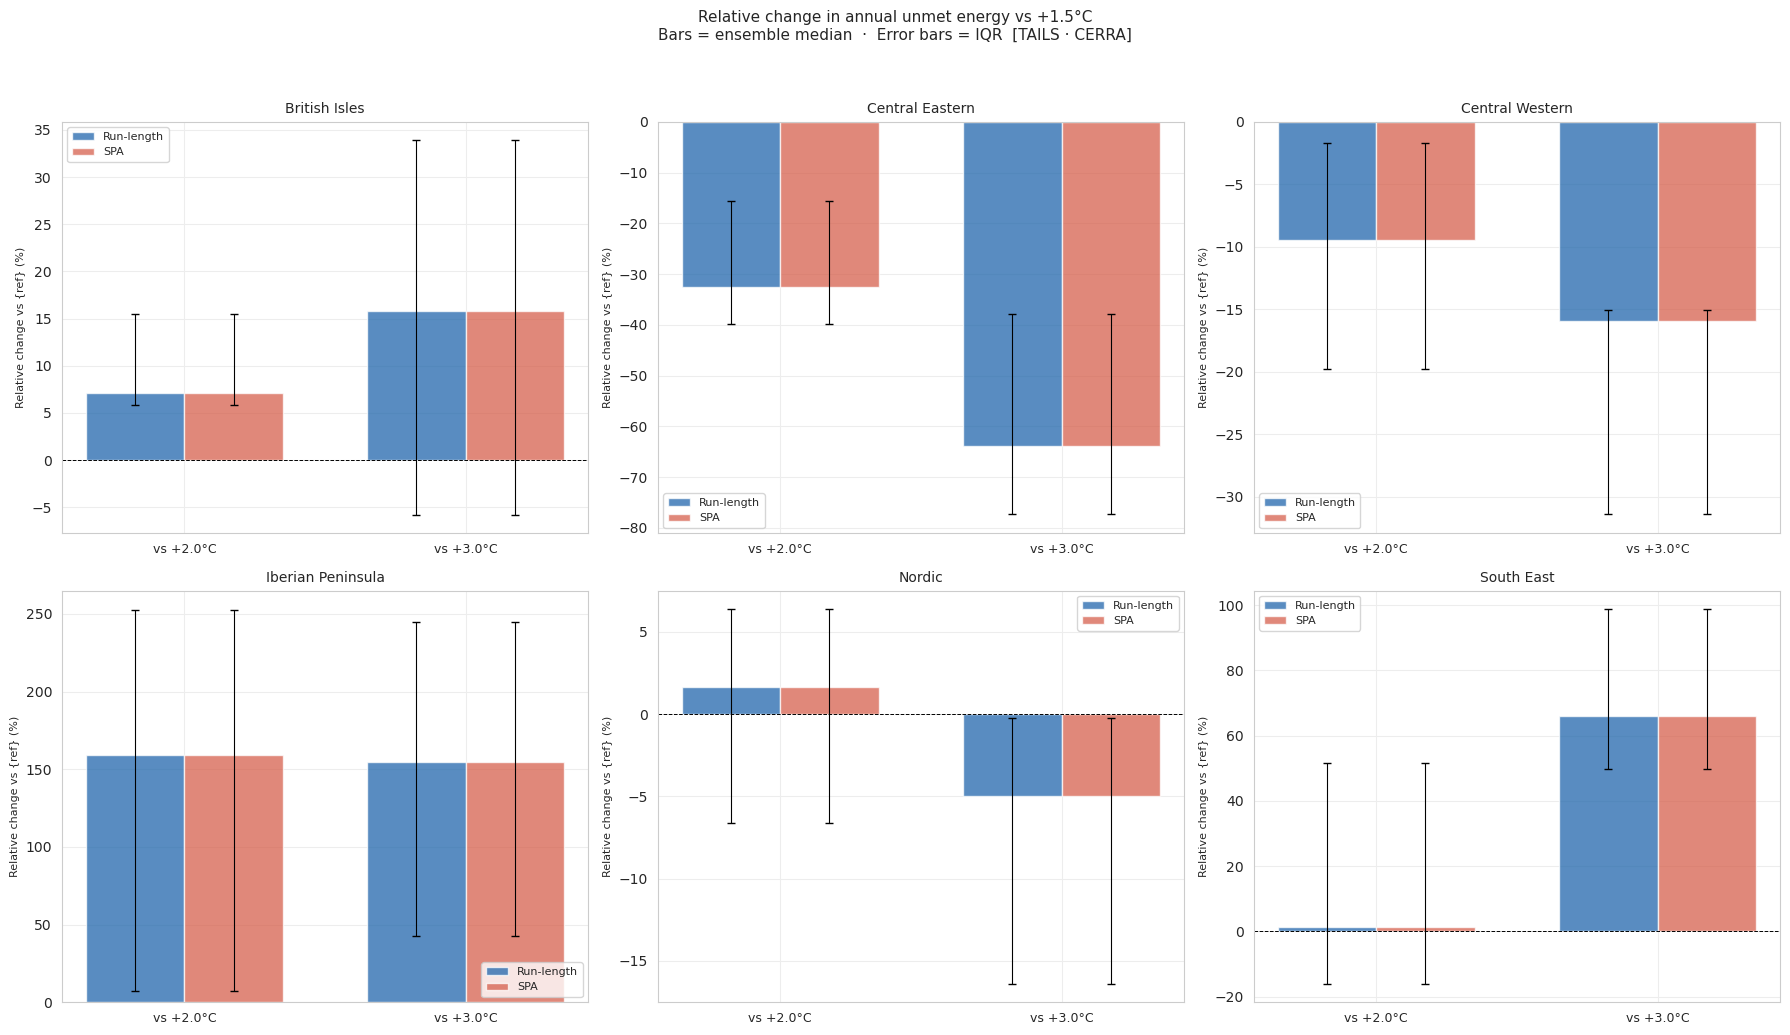

In [18]:
periods_list = list(PERIOD_SHORT.values())
ref_period   = periods_list[0]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

CHANGE_METRIC = "Total_Annual_Energy_Severity_GWh"
bar_width = 0.35

for ax, zone in zip(axes, zones):
    df_z_ref = {
        method: df_ens[method][
            (df_ens[method]["Zone"] == zone) & (df_ens[method]["Period"] == ref_period)
        ][CHANGE_METRIC]
        for method in METHODS
    }

    x_pos = np.arange(len(periods_list) - 1)
    for i, method in enumerate(METHODS):
        changes_med, changes_q25, changes_q75 = [], [], []
        ref_vals = df_z_ref[method].values

        for period in periods_list[1:]:
            fut_vals = df_ens[method][
                (df_ens[method]["Zone"] == zone) & (df_ens[method]["Period"] == period)
            ][CHANGE_METRIC].values
            # Paired relative change per model
            pct_changes = (fut_vals - ref_vals) / ref_vals.clip(min=1e-9) * 100
            changes_med.append(np.median(pct_changes))
            changes_q25.append(np.percentile(pct_changes, 25))
            changes_q75.append(np.percentile(pct_changes, 75))

        offset = (i - 0.5) * bar_width
        ax.bar(
            x_pos + offset, changes_med, width=bar_width,
            color=METHOD_COLORS[method], alpha=0.75,
            label=METHOD_LABELS[method], zorder=2,
        )
        err_lo = np.array(changes_med) - np.array(changes_q25)
        err_hi = np.array(changes_q75) - np.array(changes_med)
        ax.errorbar(
            x_pos + offset, changes_med,
            yerr=[err_lo, err_hi],
            fmt="none", color="k", capsize=3, linewidth=0.8, zorder=3,
        )

    ax.axhline(0, color="k", lw=0.7, ls="--")
    ax.set_xticks(x_pos)
    ax.set_xticklabels(
        [f"vs {p}" for p in periods_list[1:]], fontsize=9
    )
    ax.set_ylabel("Relative change vs {ref} (%)", fontsize=8)
    ax.set_title(str(zone).replace("_", " "), fontsize=10)
    ax.legend(fontsize=8)

for ax in axes[len(zones):]:
    ax.set_visible(False)

fig.suptitle(
    f"Relative change in annual unmet energy vs {ref_period}\n"
    f"Bars = ensemble median  ·  Error bars = IQR  [{THRESHOLD_METHOD} · {_thr_source}]",
    fontsize=11, y=1.03,
)
plt.tight_layout()
plt.show()